### **EX NO 8 - GENERATION OF SYNTHETIC IMAGES USING A GENERATIVE ADVERSARIAL NETWORK (GAN)**

***-SREENIDHI S (24BAD114)***

**AIM**

To implement and train a Generative Adversarial Network (GAN) to generate synthetic images by training a Generator and a Discriminator in an adversarial learning framework.

**SOFTWARE REQUIREMENTS**

•	Python

•	TensorFlow / Keras / PyTorch

•	Google Colab

•	GitHub

•	NumPy

•	Matplotlib

•	Pandas

•	Scikit-learn

**OBJECTIVES**

Students will be able to:

•	Understand the architecture and working of Generative Adversarial Networks.

•	Identify the functions of the Generator and Discriminator.

•	Prepare image datasets for GAN training.

•	Generate random noise vectors as inputs to the Generator.

•	Build and train a simple GAN using a suitable dataset.

•	Understand adversarial training and the associated loss functions.

•	Generate synthetic images and visualize the results.

•	Evaluate the quality and diversity of generated images through visual inspection.

•	Document the experiment and manage the notebook using GitHub.


**PROCEDURE**

**PART A: DATASET PREPARATION**

Perform the following tasks:

•	Load an image dataset, such as MNIST, and display sample images.

•	Explore the image dimensions and pixel-value range.

•	Normalize and reshape the images according to the GAN input requirements.

•	Prepare batches of real images for training.


In [1]:
# Ensure the very first line printed in the output matches the required format
print("Sreenidhi S - 24BAD114")

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

# Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

STUDENT_ROLL_NO = "24BAD114"
STUDENT_NAME = "Sreenidhi S"
LATENT_DIM = 100
BATCH_SIZE = 128
EPOCHS = 50

Sreenidhi S - 24BAD114


In [2]:
# PART A: DATASET PREPARATION
print(f"[{STUDENT_NAME} - {STUDENT_ROLL_NO}] Loading and preprocessing MNIST dataset...")

(X_train, _), (_, _) = tf.keras.datasets.mnist.load_data()

# Normalize pixel values to [-1, 1] to match Generator's tanh activation
X_train = (X_train.astype(np.float32) - 127.5) / 127.5
X_train = np.expand_dims(X_train, axis=-1)  # Shape: (60000, 28, 28, 1)

print(f"Dataset shape: {X_train.shape}")
print(f"Pixel range: [{X_train.min()}, {X_train.max()}]")

# Prepare batched tf.data pipeline
dataset = tf.data.Dataset.from_tensor_slices(X_train).shuffle(60000).batch(BATCH_SIZE, drop_remainder=True)


[Sreenidhi S - 24BAD114] Loading and preprocessing MNIST dataset...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Dataset shape: (60000, 28, 28, 1)
Pixel range: [-1.0, 1.0]


**PART B: IMPLEMENTING THE THE GENERATOR AND DISCRIMINATOR**

Perform the following tasks:

•	Build a Generator model to create synthetic images from random noise vectors.

•	Build a Discriminator model to classify images as real or generated.

•	Select suitable layers, activation functions, optimizer, and loss function.

•	Combine the Generator and Discriminator to construct the GAN.

•	Display the model summaries.



In [3]:
# PART B: IMPLEMENTING GENERATOR AND DISCRIMINATOR
def build_generator(latent_dim=100):
    model = models.Sequential(name=f"Generator_{STUDENT_ROLL_NO}")
    model.add(layers.Dense(256, input_dim=latent_dim))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.BatchNormalization(momentum=0.8))

    model.add(layers.Dense(512))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.BatchNormalization(momentum=0.8))

    model.add(layers.Dense(1024))
    model.add(layers.LeakyReLU(alpha=0.2))
    model.add(layers.BatchNormalization(momentum=0.8))

    model.add(layers.Dense(28 * 28 * 1, activation='tanh'))
    model.add(layers.Reshape((28, 28, 1)))
    return model

def build_discriminator(input_shape=(28, 28, 1)):
    model = models.Sequential(name=f"Discriminator_{STUDENT_ROLL_NO}")
    model.add(layers.Flatten(input_shape=input_shape))
    model.add(layers.Dense(512))
    model.add(layers.LeakyReLU(alpha=0.2))

    model.add(layers.Dense(256))
    model.add(layers.LeakyReLU(alpha=0.2))

    model.add(layers.Dense(1, activation='sigmoid'))
    return model

generator = build_generator(LATENT_DIM)
discriminator = build_discriminator()

discriminator.compile(
    loss='binary_crossentropy',
    optimizer=optimizers.Adam(learning_rate=0.0002, beta_1=0.5),
    metrics=['accuracy']
)

# Combined GAN (Generator + Discriminator)
discriminator.trainable = False  # Freeze discriminator during generator updates
gan_input = layers.Input(shape=(LATENT_DIM,))
fake_img = generator(gan_input)
gan_output = discriminator(fake_img)

gan = models.Model(gan_input, gan_output, name=f"GAN_{STUDENT_ROLL_NO}")
gan.compile(
    loss='binary_crossentropy',
    optimizer=optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
)

print("\n--- Generator Summary ---")
generator.summary()
print("\n--- Discriminator Summary ---")
discriminator.summary()



--- Generator Summary ---


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "Generator_24BAD114"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        25,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 784)            │       803,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,493,520 (5.70 MB)

 Trainable params: 1,489,936 (5.68 MB)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 533,505 (2.04 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 533,505 (2.04 MB)

**PART C: GAN TRAINING AND PERFORMANCE MONITORING**

Perform the following tasks:

•	Train the Discriminator using real and generated images.

•	Train the Generator to produce realistic images.

•	Alternate the training of both models for a suitable number of epochs.

•	Record and plot Generator and Discriminator losses.

•	Display sample generated images during training.



[Sreenidhi S - 24BAD114] Starting training for 50 epochs...


/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


Epoch 01/50 | D Loss: 2.2910 | G Loss: 0.1188
Epoch 10/50 | D Loss: 4.5592 | G Loss: 0.0041
Epoch 20/50 | D Loss: 5.1910 | G Loss: 0.0020
Epoch 30/50 | D Loss: 5.7296 | G Loss: 0.0013
Epoch 40/50 | D Loss: 6.2389 | G Loss: 0.0010
Epoch 50/50 | D Loss: 6.6311 | G Loss: 0.0008


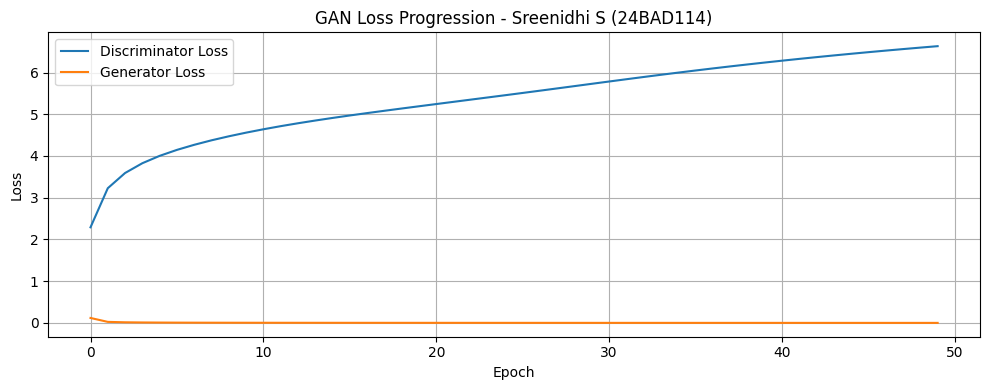

In [4]:
# PART C: GAN TRAINING AND PERFORMANCE MONITORING
real_labels = np.ones((BATCH_SIZE, 1))
fake_labels = np.zeros((BATCH_SIZE, 1))

d_losses, g_losses = [], []

print(f"\n[{STUDENT_NAME} - {STUDENT_ROLL_NO}] Starting training for {EPOCHS} epochs...")

for epoch in range(1, EPOCHS + 1):
    epoch_d_loss = []
    epoch_g_loss = []

    for real_images in dataset:
        # 1. Train Discriminator
        noise = np.random.normal(0, 1, (BATCH_SIZE, LATENT_DIM))
        fake_images = generator.predict(noise, verbose=0)

        d_loss_real = discriminator.train_on_batch(real_images, real_labels)[0]
        d_loss_fake = discriminator.train_on_batch(fake_images, fake_labels)[0]
        d_loss = 0.5 * (d_loss_real + d_loss_fake)

        # 2. Train Generator (wants Discriminator to classify fake images as real)
        noise = np.random.normal(0, 1, (BATCH_SIZE, LATENT_DIM))
        g_loss = gan.train_on_batch(noise, real_labels)
        epoch_d_loss.append(d_loss)
        epoch_g_loss.append(g_loss)

    avg_d = np.mean(epoch_d_loss)
    avg_g = np.mean(epoch_g_loss)
    d_losses.append(avg_d)
    g_losses.append(avg_g)
    if epoch % 10 == 0 or epoch == 1:
        print(f"Epoch {epoch:02d}/{EPOCHS} | D Loss: {avg_d:.4f} | G Loss: {avg_g:.4f}")

# Plot Loss Curves
plt.figure(figsize=(10, 4))
plt.plot(d_losses, label='Discriminator Loss', color='tab:blue')
plt.plot(g_losses, label='Generator Loss', color='tab:orange')
plt.title(f'GAN Loss Progression - {STUDENT_NAME} ({STUDENT_ROLL_NO})')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

**PART D: DIMENSIONALITY REDUCTION, FEATURE VISUALIZATION AND EXPERIMENT MANAGEMENT**

Perform the following tasks:

•	Provide new movie-review sentences as input to the trained LSTM model.

•	Extract latent-space representations of test samples using the trained Encoder.

•	Generate synthetic images using the trained Generator.

•	Display and compare generated images with original dataset samples.

•	Observe the quality, diversity, and recognizability of generated images.

•	Document the experiment and upload the notebook to GitHub.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step


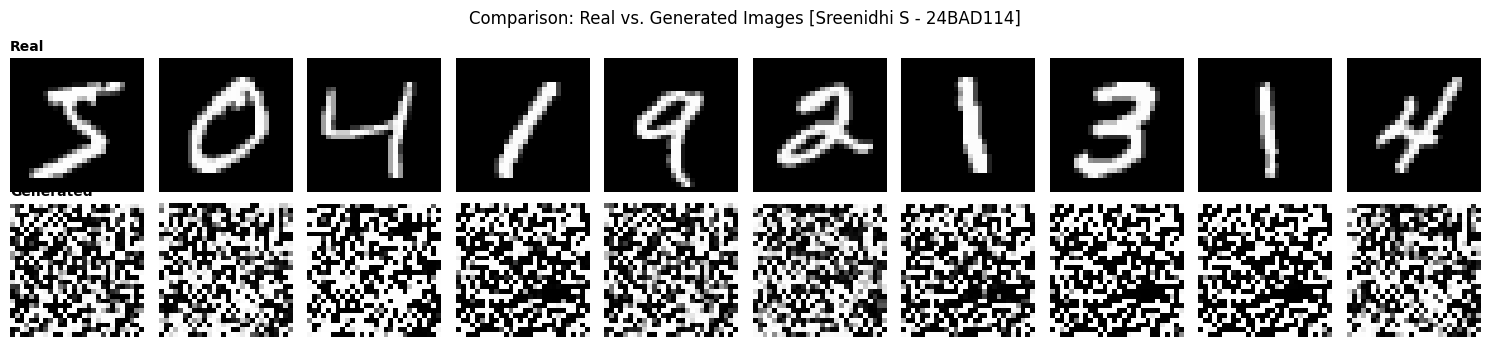

In [5]:
# PART D: EVALUATION & COMPARISON
# Generate synthetic images
eval_noise = np.random.normal(0, 1, (10, LATENT_DIM))
synthetic_images = generator.predict(eval_noise)

fig, axes = plt.subplots(2, 10, figsize=(15, 3.5))
for i in range(10):
    # Top row: Real samples
    axes[0, i].imshow(X_train[i].squeeze(), cmap='gray')
    axes[0, i].axis('off')
    if i == 0:
        axes[0, i].set_title("Real", loc='left', fontsize=10, fontweight='bold')

    # Bottom row: Generated samples
    axes[1, i].imshow((synthetic_images[i].squeeze() * 127.5 + 127.5).astype(np.uint8), cmap='gray')
    axes[1, i].axis('off')
    if i == 0:
        axes[1, i].set_title("Generated", loc='left', fontsize=10, fontweight='bold')

plt.suptitle(f"Comparison: Real vs. Generated Images [{STUDENT_NAME} - {STUDENT_ROLL_NO}]", fontsize=12)
plt.tight_layout()
plt.show()